# Risk and Welfare at Second Order

A first-order solution is linear in the shocks, so it has certainty equivalence: the decision rules do not depend on how volatile the economy is, a positive shock has the mirror-image response of a negative one, and the average of every variable is its deterministic steady state. Agents in such a model behave as if they faced no risk at all. Three questions a policymaker asks therefore have no answer at first order: how uncertainty moves average outcomes, whether booms and busts are symmetric, and which policy rule delivers the highest expected welfare.

A second-order solution keeps the quadratic terms of the Taylor expansion,

$$
\hat{y}_t = g_x \hat{x}_{t-1} + g_u \varepsilon_t + \tfrac{1}{2} \left( g_{xx} (\hat{x}_{t-1} \otimes \hat{x}_{t-1}) + 2 g_{xu} (\hat{x}_{t-1} \otimes \varepsilon_t) + g_{uu} (\varepsilon_t \otimes \varepsilon_t) + g_{\sigma\sigma} \right),
$$

where $\hat{x}$ are the state variables and $g_{\sigma\sigma}$ is the risk correction, a constant that grows with the variance of the shocks. Schmitt-Grohe and Uribe {cite:p}`schmitt-grohe-uribe-2004` show that $g_{\sigma\sigma}$ is the only coefficient of a second-order approximation that depends on the size of the shocks. This notebook solves a New Keynesian model at second order and uses the solution to answer all three questions.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pytensor
import pytensor.tensor as pt
import xarray as xr

from matplotlib.colors import Normalize
from pytensor.graph.replace import graph_replace

import gEconpy as ge
import gEconpy.plotting as gp

from gEconpy.model.pruning import pruned_second_order_moments

gp.set_matplotlib_style()
RANDOM_SEED = sum(map(ord, "second order"))
rng = np.random.default_rng(RANDOM_SEED)

## The Model

The model is a cashless New Keynesian economy with Calvo pricing {cite:p}`calvo-1983`, written in its nonlinear recursive form. Households value consumption and dislike work, and their lifetime utility,

$$
U_t = \frac{C_t^{1 - \sigma}}{1 - \sigma} - \theta \frac{N_t^{1 + \chi}}{1 + \chi} + \beta E_t U_{t+1},
$$

is kept as a model variable, so its mean is the expected welfare of the economy. Firms that reset their price choose $P^*_t$ from two discounted sums, $\hat{X}_{1,t}$ and $\hat{X}_{2,t}$, and staggered pricing leaves a dispersion of relative prices,

$$
\nu_{p,t} = (1 - \phi) P^{*\,-\epsilon_t}_t + \phi \pi_t^{\epsilon_t} \nu_{p,t-1},
$$

which wastes labor: producing $Y_t$ takes $\nu_{p,t} Y_t$ hours. At a zero-inflation steady state, $\nu_p = 1$ and its first derivative with respect to inflation is zero. A first-order solution therefore has no dispersion at all, whatever the shocks. Dispersion first appears at second order, as the square of inflation, and it is the channel through which inflation volatility costs welfare.

The model has three shocks: technology `epsilon_A`, a markup shock `epsilon_markup` on the elasticity of substitution, and a monetary policy shock `epsilon_i` in the Taylor rule.

In [2]:
gcn_path = ge.data.get_example_gcn("nk_welfare")
model = ge.model_from_gcn(gcn_path, verbose=False)
model.steady_state()

{'A_ss': np.float64(1.0),
 'C_ss': np.float64(0.9764540896763105),
 'N_ss': np.float64(0.9764540896763105),
 'P_reset_ss': np.float64(1.0),
 'SDF_ss': np.float64(0.99),
 'U_ss': np.float64(-100.11357187078711),
 'X_hat_1_ss': np.float64(3.447322470172322),
 'X_hat_2_ss': np.float64(3.7920547171895547),
 'Y_ss': np.float64(0.9764540896763105),
 'epsilon_tv_ss': np.float64(11.0),
 'i_ss': np.float64(0.010101010101010166),
 'interest_shock_ss': np.float64(1.0),
 'lambda_ss': np.float64(1.0740994986439416),
 'mc_ss': np.float64(0.9090909090909091),
 'nu_p_ss': np.float64(1.0),
 'pi_ss': np.float64(1.0),
 'w_ss': np.float64(0.9090909090909091)}

## Solving at Second Order

`solve_model(order=2)` returns a `SecondOrderPerturbationSolution`. It holds the first-order solution, $g_x$ and $g_u$, together with the three second-order tensors. Following Dynare, the rows are every model variable in decision-rule order, and the columns run over the state variables only, the variables that appear with a lag. Variables with a positive steady state are log-linearized, so their deviations are log deviations. Welfare $U$ has a negative steady state and stays in levels. The net interest rate `i` is close to zero, where a log deviation is hard to read, so it is solved in levels too.

The first call builds and compiles the second-order graph, which takes about a minute. Later solves of the same model, at any parameter values, reuse the compiled function.

In [3]:
solve_kwargs = {"not_loglin_variables": ["i"], "verbose": False}
first_order = model.solve_model(**solve_kwargs, return_matrices=False)
second_order = model.solve_model(order=2, **solve_kwargs)

dr_order = second_order.dr_order
state_names = [second_order.variable_names[i] for i in dr_order.var_order[dr_order.lag_positions]]
print(f"State variables: {state_names}")

pd.Series(
    {
        "ghx": second_order.ghx.shape,
        "ghu": second_order.ghu.shape,
        "ghxx": second_order.ghxx.shape,
        "ghxu": second_order.ghxu.shape,
        "ghuu": second_order.ghuu.shape,
    },
    name="shape",
)

State variables: ['A', 'interest_shock', 'nu_p', 'epsilon_tv', 'lambda']


ghx        (17, 5)
ghu        (17, 3)
ghxx    (17, 5, 5)
ghxu    (17, 5, 3)
ghuu    (17, 3, 3)
Name: shape, dtype: object

In the rows for price dispersion, the first-order response to every shock, $g_u$, is zero, and only the persistence of past dispersion, through $g_x$, survives at first order. The quadratic terms are large.

In [4]:
dr_names = [second_order.variable_names[i] for i in dr_order.var_order]
terms = ["ghx", "ghu", "ghxx", "ghxu", "ghuu"]

pd.DataFrame(
    {
        name: [np.abs(getattr(second_order, term)[dr_names.index(name)]).max() for term in terms]
        for name in ["nu_p", "pi", "Y"]
    },
    index=pd.Index(terms, name="largest |coefficient|"),
)

,nu_p,pi,Y
largest |coefficient|,,,
ghx,7.500000e-01,0.421555,0.316166
ghu,4.576199e-16,0.468395,0.373153
ghxx,5.864391e+00,1.888242,0.830970
ghxu,6.515990e+00,3.776485,1.661941
ghuu,7.239989e+00,4.196094,1.846601


## Impulse Responses

At second order, `impulse_response_function` runs the shock through the pruned recursion of Kim, Kim, Schaumburg and Sims {cite:p}`kim-2008`. Pruning evaluates the quadratic terms on the first-order part of the path only, which keeps simulated paths stable however long they run. The response starts from the steady state with no other shocks, so it carries no risk correction.

A monetary tightening and an easing of the same size are mirror images at first order. At second order both raise price dispersion, because dispersion grows with the square of inflation whatever its sign.

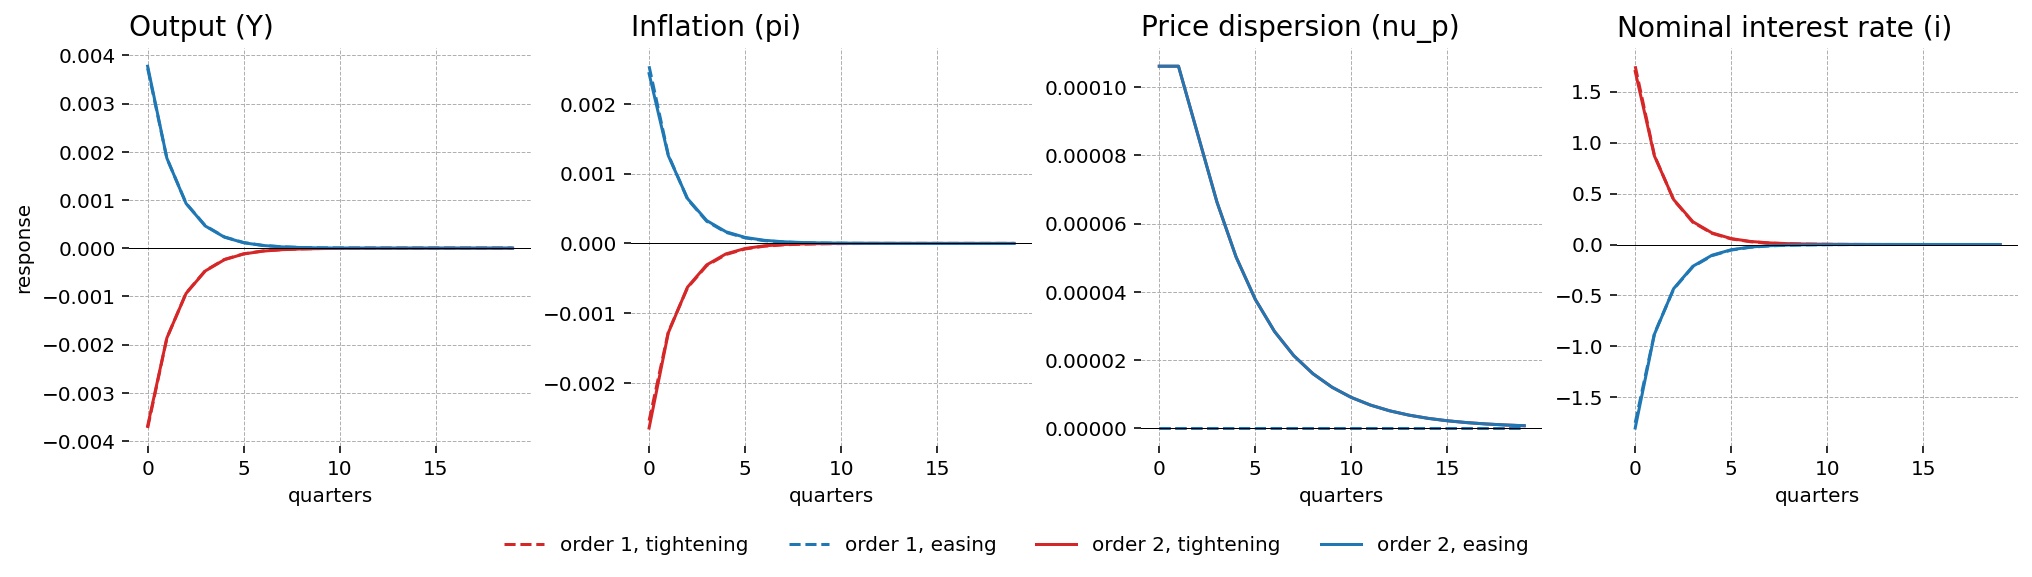

In [5]:
SHOCK_STD = {"epsilon_A": 0.01, "epsilon_i": 0.0025, "epsilon_markup": 0.05}
impulse = 4 * SHOCK_STD["epsilon_i"]
VARIABLE_TITLES = {
    "Y": "Output (Y)",
    "pi": "Inflation (pi)",
    "nu_p": "Price dispersion (nu_p)",
    "mc": "Marginal cost (mc)",
    "w": "Real wage (w)",
    "i": "Nominal interest rate (i)",
}


def plotted_response(irf, name):
    """Log deviation, or the annualized percentage-point deviation for the interest rate."""
    scale = 400 if name == "i" else 1
    return scale * irf["deviation"].sel(variable=name)


responses = {
    (order, sign): ge.impulse_response_function(
        model=model,
        solution=solution,
        simulation_length=20,
        shock_size={"epsilon_i": sign * impulse},
    ).sel(shock="epsilon_i")
    for order, solution in [(1, first_order), (2, second_order)]
    for sign in (1, -1)
}

plot_variables = ["Y", "pi", "nu_p", "i"]
fig, axes = plt.subplots(nrows=1, ncols=len(plot_variables), figsize=(14, 3.5), sharex=True)
for ax, name in zip(axes, plot_variables, strict=True):
    for (order, sign), irf in responses.items():
        ax.plot(
            plotted_response(irf, name),
            color="tab:red" if sign > 0 else "tab:blue",
            linestyle="-" if order == 2 else "--",
            label=f"order {order}, {'tightening' if sign > 0 else 'easing'}",
        )
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_title(VARIABLE_TITLES[name], loc="left", fontsize=14)
    ax.set_xlabel("quarters")

axes[0].set_ylabel("response")
fig.legend(
    *axes[0].get_legend_handles_labels(),
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=4,
    frameon=False,
);

Outside price dispersion, the two orders are hard to tell apart, because the linear part of the response dominates. Adding the responses to a tightening and an easing of the same size isolates what second order adds. A shock $\varepsilon$ hitting the economy at its steady state starts a first-order path that is linear in $\varepsilon$ and a second-order path that is quadratic in it. Writing the response as $L \varepsilon + Q(\varepsilon)$, flipping the sign of the shock gives $-L \varepsilon + Q(\varepsilon)$, so the sum of the two responses is

$$
y(\varepsilon) + y(-\varepsilon) = 2 Q(\varepsilon).
$$

The linear parts cancel, leaving twice the second-order part of the response, and at first order the sum is zero in every period. Because $Q$ is quadratic, doubling the shock doubles the linear part of the response and quadruples the sum, so the asymmetry grows faster than the shock.

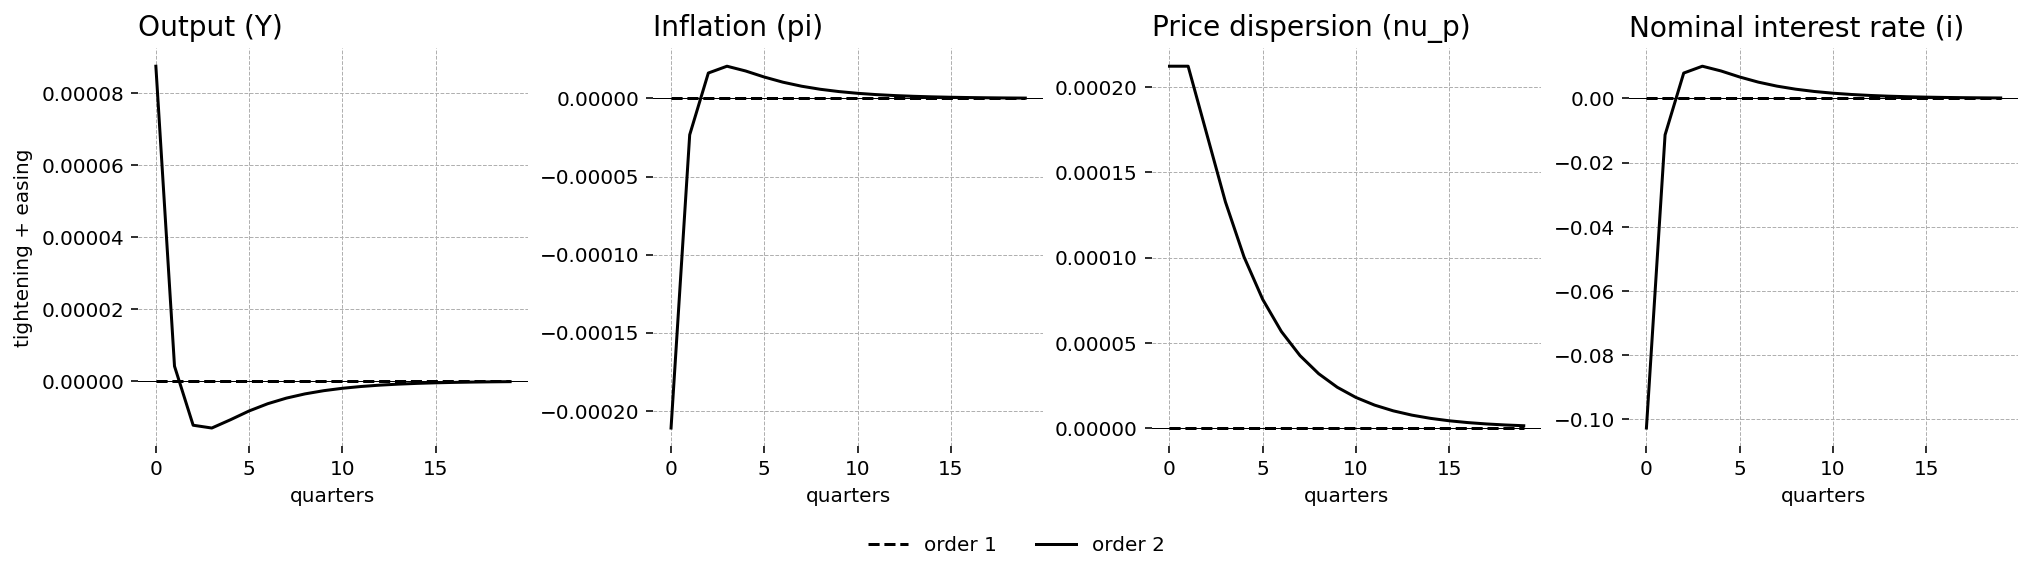

In [6]:
fig, axes = plt.subplots(nrows=1, ncols=len(plot_variables), figsize=(14, 3.5), sharex=True)
for ax, name in zip(axes, plot_variables, strict=True):
    for order in (1, 2):
        asymmetry = plotted_response(responses[order, 1], name) + plotted_response(responses[order, -1], name)
        ax.plot(asymmetry, color="black", linestyle="-" if order == 2 else "--", label=f"order {order}")
    ax.axhline(0, color="black", linewidth=0.5)
    ax.ticklabel_format(axis="y", style="plain")
    ax.set_title(VARIABLE_TITLES[name], loc="left", fontsize=14)
    ax.set_xlabel("quarters")

axes[0].set_ylabel("tightening + easing")
fig.legend(
    *axes[0].get_legend_handles_labels(),
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    frameon=False,
);

Price dispersion has no linear part, so its sum is exactly twice either response. For the other variables the sum is between 2 and 8 percent of the impact response. On impact, an easing raises output by more than a tightening lowers it, and a tightening lowers inflation and the interest rate by more than an easing raises them. From quarter 2 on the signs reverse: output is lower after either shock while price dispersion is still elevated, and inflation and the interest rate are higher.

Policy shocks come with both signs, and their average linear effect is zero. The quadratic part takes the same value whichever way the shock goes, so averaged over many shocks, $Q(\varepsilon)$, half the sum plotted above, moves the mean of every variable away from its steady state. Unpredictable monetary policy therefore has a cost even when it is unbiased, because every surprise, up or down, adds to price dispersion. The next section measures the full shift in the means, which also includes the risk correction that an impulse response leaves out.

## Risk and the Stochastic Steady State

`simulate` draws Gaussian shocks and runs them through the pruned recursion. Unlike an impulse response, a simulation includes the risk correction $g_{\sigma\sigma}$, which `ghs2` evaluates at the shock covariance. The correction is linear in the covariance, because it is a fixed operator applied to the vectorized covariance:

In [7]:
shock_cov = np.diag([SHOCK_STD[name] ** 2 for name in second_order.shock_names])
risk_correction = second_order.ghs2(shock_cov)

np.allclose(second_order.ghs2(2 * shock_cov), 2 * risk_correction)

True

Together with the variance of the shocks, which the quadratic terms turn into a nonzero average, the risk correction moves the mean of every variable away from the deterministic steady state, so the economy fluctuates around a stochastic steady state of its own. `stationary_mean` computes this mean in closed form from the pruned system of Andreasen, Fernandez-Villaverde and Rubio-Ramirez {cite:p}`andreasen-2018`, and the average of a long simulation converges to it. A first-order solution's stationary mean is the steady state.

In [8]:
BURN_IN = 100
simulations = {
    order: ge.simulate(
        model=model,
        solution=solution,
        n_simulations=200,
        simulation_length=BURN_IN + 500,
        shock_std_dict=SHOCK_STD,
        random_seed=rng,
    ).isel(time=slice(BURN_IN, None))
    for order, solution in [(1, first_order), (2, second_order)]
}

moment_variables = ["Y", "pi", "nu_p", "mc", "i"]
stationary_mean = ge.stationary_mean(model=model, solution=second_order, shock_std_dict=SHOCK_STD)
pd.DataFrame(
    {
        "stationary mean": stationary_mean["deviation"].to_pandas(),
        "simulated mean": simulations[2].mean(["simulation", "time"]).to_pandas(),
        "first-order simulated mean": simulations[1].mean(["simulation", "time"]).to_pandas(),
    }
).loc[moment_variables]

,stationary mean,simulated mean,first-order simulated mean
variable,,,
Y,-0.003811,-0.004025,6.225171e-05
pi,0.003762,0.004043,-8.220321e-05
nu_p,0.008118,0.008089,-3.622243e-19
mc,-0.007124,-0.006809,3.673719e-05
i,0.003856,0.004181,-1.012185e-04


Inflation averages 0.38 percent per quarter above the central bank's target, about 1.5 percentage points a year, and marginal cost averages 0.7 percent below its steady state, so the average markup is 0.7 percent above the one firms would charge without shocks. A firm that cannot reset its price for several quarters loses more from a price that turns out too low than from one that turns out too high, so under uncertainty it sets a higher price. Fernandez-Villaverde, Guerron-Quintana, Kuester and Rubio-Ramirez {cite:p}`fernandez-villaverde-2015` call this the upward pricing bias. The higher markups, together with 0.8 percent of price dispersion that wastes labor, leave output 0.4 percent below its steady state on average, and the Taylor rule's response to the higher average inflation keeps the nominal rate about 1.5 percentage points a year above its steady state.

Each row below follows 40 of the 200 second-order simulated paths for 120 quarters. The vertical line marks one quarter, and the panel to its right shows the distribution of all 200 simulations at that quarter, at second order and at first order, with the plotted paths' values marked at its base.

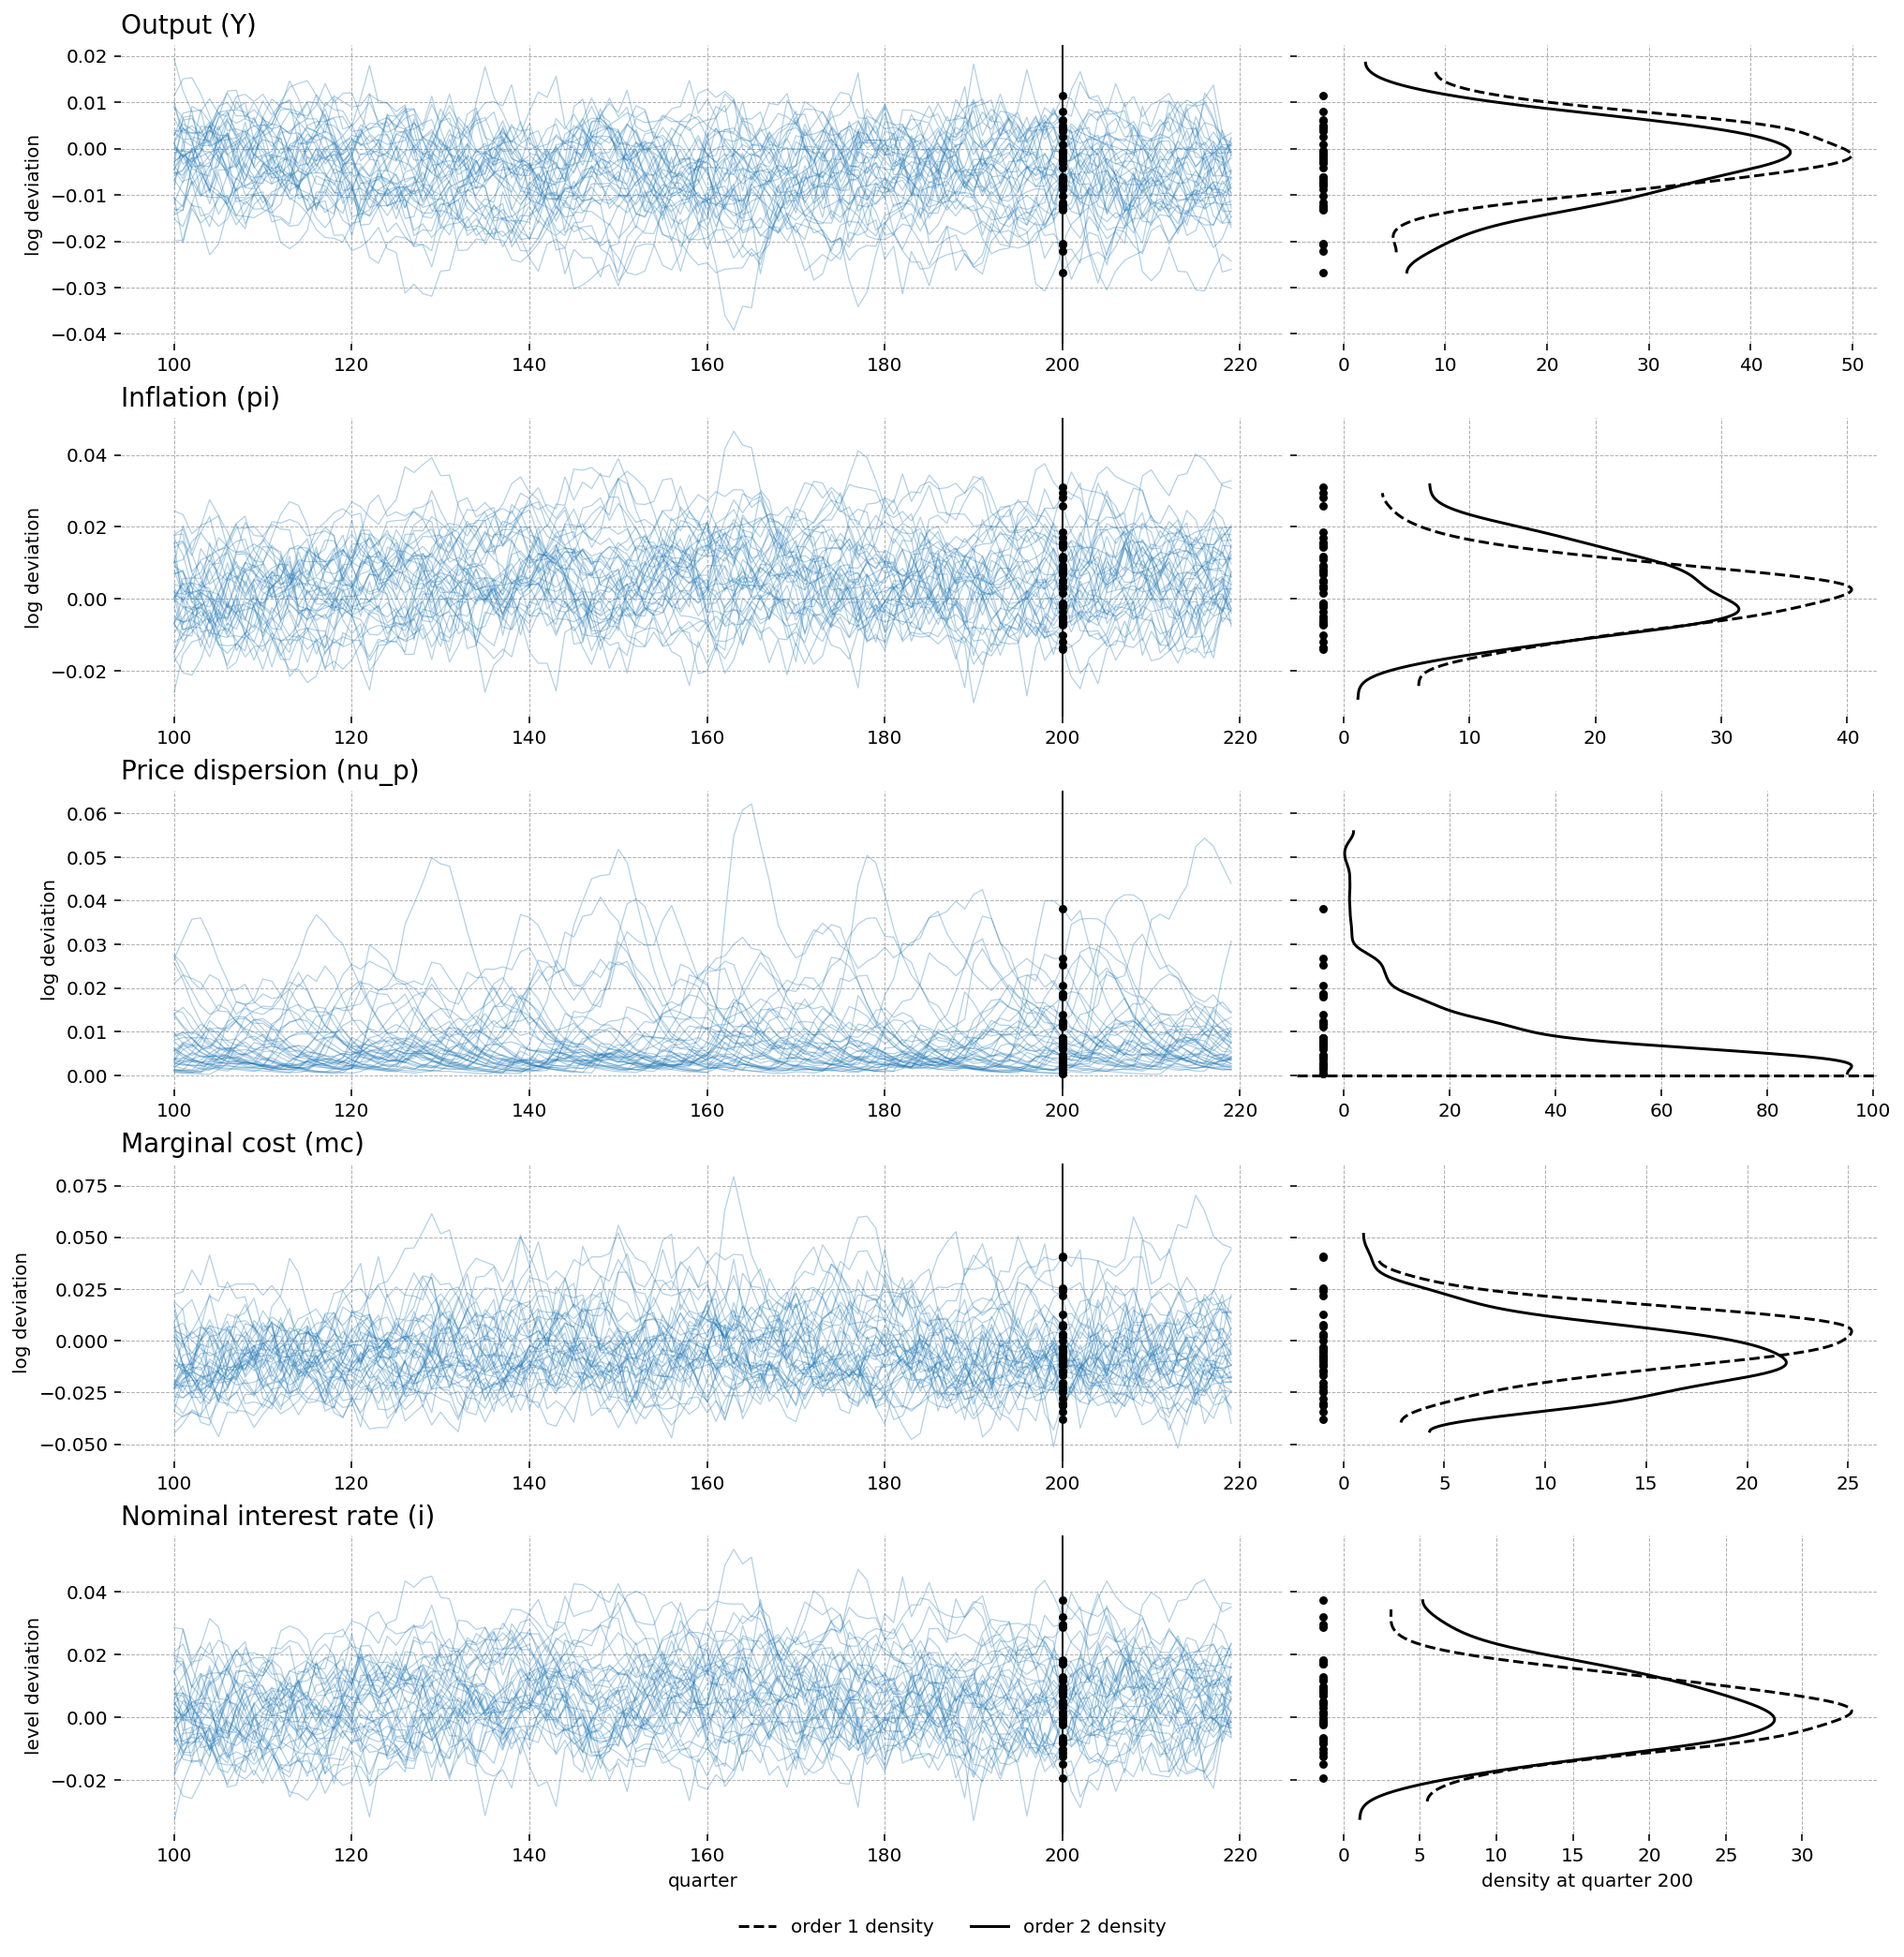

In [9]:
N_PATHS = 40
WINDOW = 120
SLICE = 100

windows = simulations[2].sel(variable=moment_variables).isel(time=slice(0, WINDOW))
slice_time = windows["time"].values[SLICE]
cross_sections = {order: simulations[order].sel(variable=moment_variables, time=slice_time) for order in (1, 2)}
kdes = {order: az.kde(cross_section, dim="simulation") for order, cross_section in cross_sections.items()}

fig = plt.figure(figsize=(14, 14))
grid = fig.add_gridspec(nrows=len(moment_variables), ncols=3)
for row, name in enumerate(moment_variables):
    paths_ax = fig.add_subplot(grid[row, :2])
    density_ax = fig.add_subplot(grid[row, 2], sharey=paths_ax)

    window = windows.sel(variable=name).isel(simulation=slice(0, N_PATHS))
    shown_values = window.sel(time=slice_time).values
    paths_ax.plot(window["time"], window.transpose("time", "simulation"), color="C0", linewidth=0.6, alpha=0.35)
    paths_ax.axvline(slice_time, color="black", linewidth=1)
    paths_ax.scatter(np.full(N_PATHS, slice_time), shown_values, color="black", s=12, zorder=3)
    paths_ax.set_title(VARIABLE_TITLES[name], loc="left", fontsize=14)
    paths_ax.set_ylabel("level deviation" if name == "i" else "log deviation")

    peak = 0.0
    for order, kde in kdes.items():
        linestyle = "-" if order == 2 else "--"
        # First-order price dispersion is zero in every period, so it is drawn as the line at zero.
        if cross_sections[order].sel(variable=name).std() < 1e-12:
            density_ax.axhline(0, color="black", linestyle=linestyle, label=f"order {order} density")
            continue
        support, density = (kde.sel(variable=name, plot_axis=axis) for axis in ("x", "y"))
        peak = max(peak, float(density.max()))
        density_ax.plot(density, support, color="black", linestyle=linestyle, label=f"order {order} density")
    density_ax.scatter(np.full(N_PATHS, -0.04 * peak), shown_values, color="black", s=12, zorder=3)
    density_ax.tick_params(labelleft=False)

    if row == len(moment_variables) - 1:
        paths_ax.set_xlabel("quarter")
        density_ax.set_xlabel(f"density at quarter {slice_time}")

fig.legend(
    *density_ax.get_legend_handles_labels(),
    loc="lower center",
    bbox_to_anchor=(0.5, -0.03),
    ncol=2,
    frameon=False,
);

`stationary_covariance_matrix` and `autocovariance_matrix` return the moments of the pruned system at order 2. The quadratic terms add variance of their own, and they skew the distributions: price dispersion can only rise above its first-order value of zero.

In [10]:
def standard_deviations(solution):
    covariance = ge.stationary_covariance_matrix(model=model, solution=solution, shock_std_dict=SHOCK_STD)
    # The first-order variance of price dispersion is zero up to rounding, which can leave it slightly negative.
    return pd.Series(np.sqrt(np.diag(covariance).clip(min=0)), index=covariance.index)


pd.DataFrame(
    {
        "order 1": standard_deviations(first_order),
        "order 2": standard_deviations(second_order),
        "order 2, simulated": simulations[2].std(["simulation", "time"]).to_pandas(),
    }
).loc[moment_variables]

,order 1,order 2,"order 2, simulated"
Y,8.303261e-03,0.008341,0.008363
pi,1.109050e-02,0.011142,0.011160
nu_p,8.251897e-17,0.008671,0.008705
mc,1.581414e-02,0.016807,0.017010
i,1.267547e-02,0.012741,0.012764


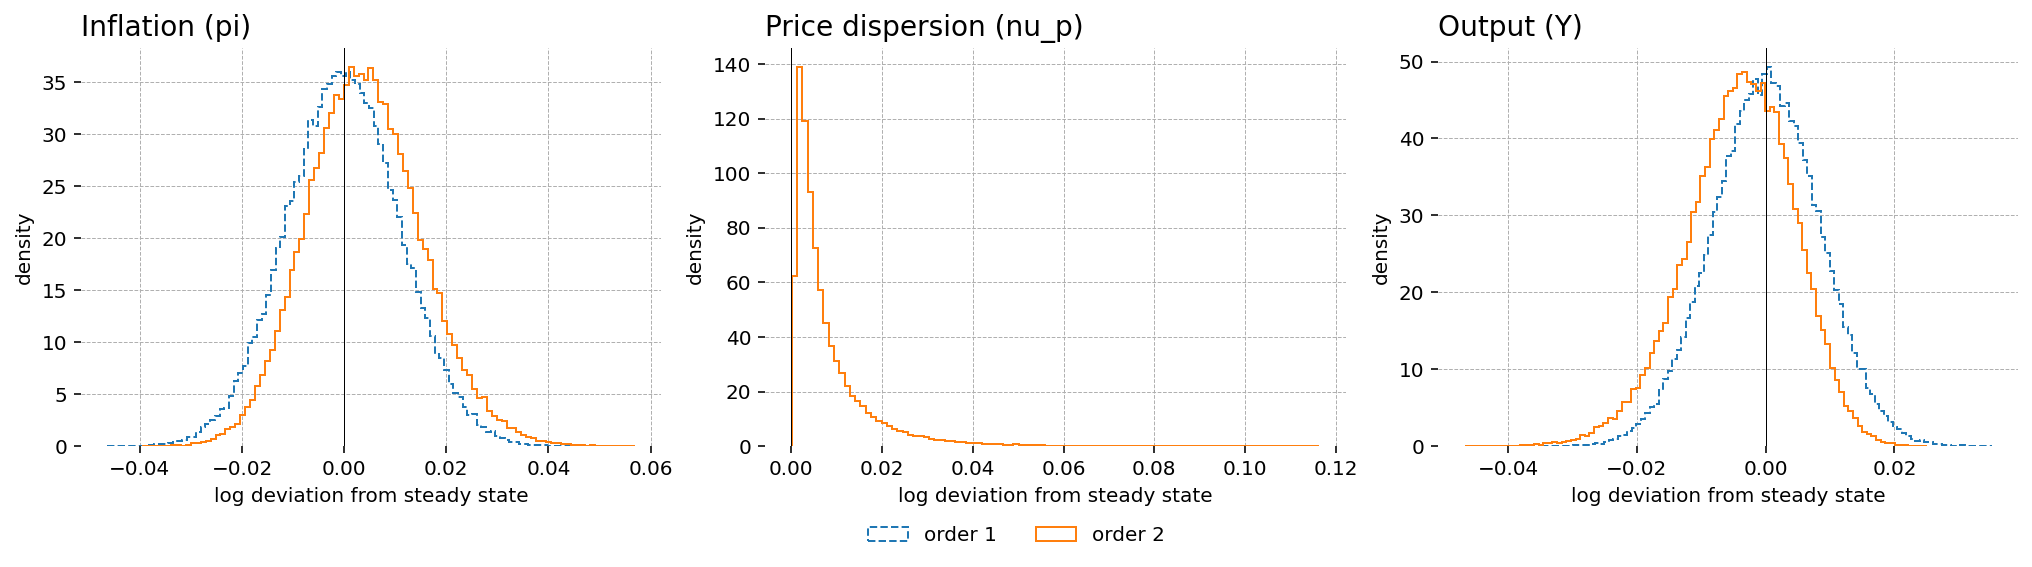

In [11]:
histogram_variables = ["pi", "nu_p", "Y"]
fig, axes = plt.subplots(nrows=1, ncols=len(histogram_variables), figsize=(14, 3.5))
for ax, name in zip(axes, histogram_variables, strict=True):
    # First-order price dispersion is zero in every period, so it is drawn as the line at zero.
    orders = [2] if name == "nu_p" else [1, 2]
    for order in orders:
        ax.hist(
            simulations[order].sel(variable=name).values.ravel(),
            bins=100,
            density=True,
            histtype="step",
            color=f"C{order - 1}",
            linestyle="-" if order == 2 else "--",
            label=f"order {order}",
        )
    ax.axvline(0, color="black", linewidth=0.5)
    ax.set_title(VARIABLE_TITLES[name], loc="left", fontsize=14)
    ax.set(xlabel="log deviation from steady state", ylabel="density")

fig.legend(
    *axes[0].get_legend_handles_labels(),
    loc="lower center",
    bbox_to_anchor=(0.5, -0.1),
    ncol=2,
    frameon=False,
);

## Welfare and Monetary Policy Rules

The most common use of second-order solutions is ranking policies by expected welfare, following Schmitt-Grohe and Uribe {cite:p}`schmitt-grohe-uribe-2007`. At first order the mean of lifetime utility $U$ is its steady state under every policy rule, so every rule delivers the same expected welfare. Kim and Kim {cite:p}`kim-kim-2003` show that welfare comparisons computed from first-order solutions can even rank policies in the wrong order. At second order, the mean of $U$ includes the average losses from fluctuations: higher markups, wasted labor from price dispersion, and the curvature of utility itself.

Welfare is easier to read as a consumption equivalent: the permanent percentage cut $\lambda$ in steady-state consumption that would make a household without shocks exactly as well off as the expected household in the fluctuating economy,

$$
\frac{\left((1 - \lambda) C_{ss}\right)^{1 - \sigma}}{(1 - \sigma)(1 - \beta)} - \frac{\theta N_{ss}^{1 + \chi}}{(1 + \chi)(1 - \beta)} = E[U].
$$

`symbolic_solution` returns the steady state and the second-order solution as PyTensor graphs of the model's parameters, and `pruned_second_order_moments` turns them into the stationary mean of the pruned system. Together they give $\lambda$ as one graph. The first cell below fixes every parameter except the Taylor rule coefficients at its calibrated value and compiles the graph once. The second evaluates it on a grid of inflation responses $\phi_\pi$ and output responses $\phi_Y$. The steady state does not depend on the Taylor rule coefficients, so every rule is measured against the same benchmark.

In [12]:
solution = model.symbolic_solution(order=2, **solve_kwargs)
parameters = solution.parameters
dr_names = [solution.variable_names[i] for i in solution.dr_order.var_order]
shock_cov_graph = pt.diag(pt.as_tensor([SHOCK_STD[name] ** 2 for name in solution.shock_names]))

stationary_mean_dr, _ = pruned_second_order_moments(
    ghx=solution.ghx,
    ghu=solution.ghu,
    ghxx=solution.ghxx,
    ghxu=solution.ghxu,
    ghuu=solution.ghuu,
    ghs2_operator=solution.ghs2_operator,
    shock_cov=shock_cov_graph,
    state_positions=solution.dr_order.lag_positions,
    n_lags=1,
)
U_ss, C_ss, N_ss = (solution.steady_state[solution.variable_names.index(name)] for name in ["U", "C", "N"])
beta, sigma, theta, chi = (parameters[name] for name in ["beta", "sigma", "theta", "chi"])

# U has a negative steady state, so it is not log-linearized and its mean deviation adds to its level.
expected_welfare = U_ss + stationary_mean_dr[dr_names.index("U")]
labor_disutility = theta * N_ss ** (1 + chi) / (1 + chi)
consumption_share = ((1 - beta) * expected_welfare + labor_disutility) * (1 - sigma) / C_ss ** (1 - sigma)
welfare_cost = 100 * (1 - consumption_share ** (1 / (1 - sigma)))

policy_parameters = ["phi_pi", "phi_Y"]
calibration = model.parameters()
welfare_cost = graph_replace(
    welfare_cost,
    {
        node: pt.constant(calibration[name], dtype=node.dtype)
        for name, node in parameters.items()
        if name not in policy_parameters
    },
    strict=False,
)
f_welfare_cost = pytensor.function([parameters[name] for name in policy_parameters], welfare_cost)

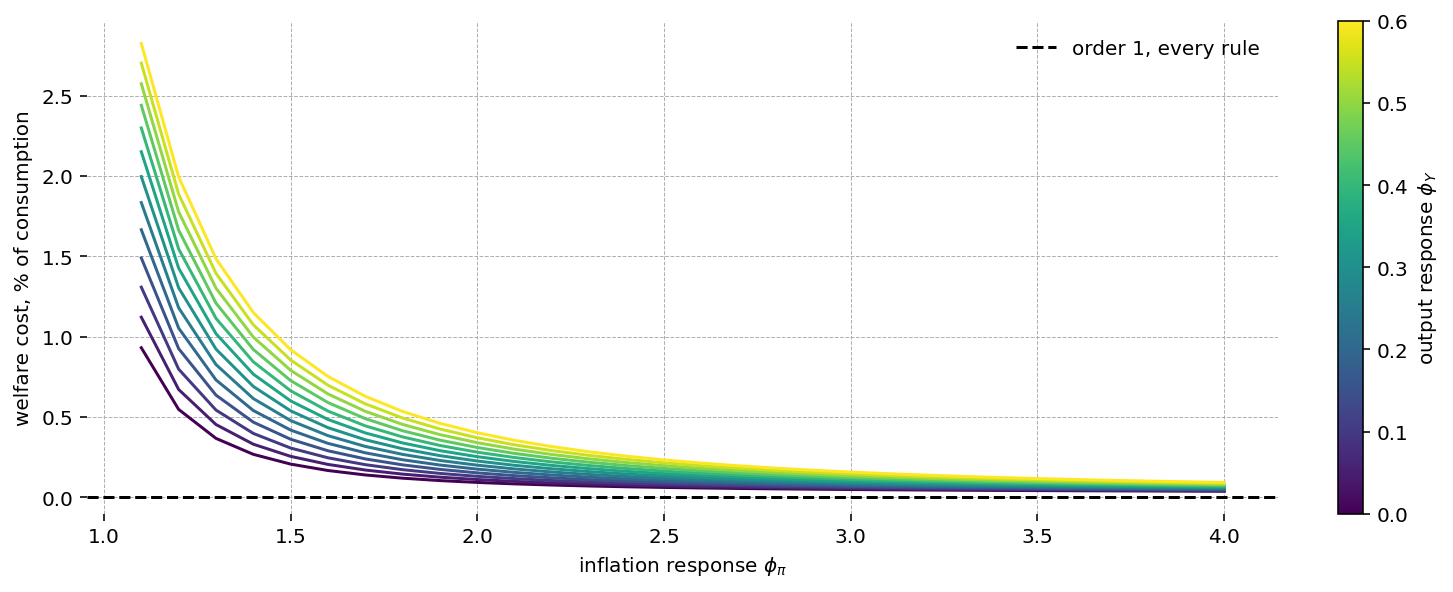

In [13]:
inflation_responses = np.linspace(1.1, 4.0, 30)
output_responses = np.linspace(0.0, 0.6, 13)
welfare_costs = pd.DataFrame(
    {phi_Y: [float(f_welfare_cost(phi_pi, phi_Y)) for phi_pi in inflation_responses] for phi_Y in output_responses},
    index=pd.Index(inflation_responses, name="phi_pi"),
)

norm = Normalize(vmin=output_responses.min(), vmax=output_responses.max())
fig, ax = plt.subplots(figsize=(10, 4))
for phi_Y in output_responses:
    ax.plot(welfare_costs.index, welfare_costs[phi_Y], color=plt.colormaps["viridis"](norm(phi_Y)))
ax.axhline(0, color="black", linestyle="--", label="order 1, every rule")
ax.set(xlabel=r"inflation response $\phi_\pi$", ylabel="welfare cost, % of consumption")
ax.legend(loc="upper right", frameon=False)

colorbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="viridis"), ax=ax)
colorbar.set_label(r"output response $\phi_Y$");

At first order every rule costs nothing, because the first-order mean of $U$ is its steady state. At second order the calibrated rule, $\phi_\pi = 1.5$ and $\phi_Y = 0.5$, costs 0.79 percent of consumption every period. Dropping the output response cuts that to 0.21 percent, and responding to inflation more aggressively lowers it further, to 0.04 percent at $\phi_\pi = 4$ with no output response. On this grid welfare rises steadily with the inflation response and falls with the output response, the pattern Schmitt-Grohe and Uribe {cite:p}`schmitt-grohe-uribe-2007` find for optimal simple rules. Leaning against inflation keeps price dispersion and markup distortions small, while responding to output moves the interest rate against technology shocks that the economy should absorb.

The shocks in this notebook are larger than estimated ones, so the welfare costs are large in absolute terms. A first-order solution cannot rank the rules at all.

### Responses across Taylor rules

The welfare ranking shows up in the impulse responses. The cells below solve the model at second order across a grid of each Taylor rule coefficient and trace the response to a one-standard-deviation technology shock. The shock raises output and lowers marginal cost, so inflation falls. A stronger response to inflation offsets that fall with a smaller cut in the interest rate, holding inflation and price dispersion close to zero. A stronger response to output leans against the efficient rise in output. Policy is tighter relative to the shock, inflation falls further, and price dispersion rises with the size of the deflation, even though the interest rate ends up lower because inflation does.

In [14]:
sweep_variables = ["Y", "pi", "nu_p", "mc", "w", "i"]
technology_impulse = {"epsilon_A": SHOCK_STD["epsilon_A"]}


def technology_responses(parameter, values, **fixed_parameters):
    """Second-order responses to a technology shock, one per value of ``parameter``, stacked on a dimension."""
    responses = [
        ge.impulse_response_function(
            model=model,
            solution=model.solve_model(order=2, **{parameter: value}, **fixed_parameters, **solve_kwargs),
            simulation_length=20,
            shock_size=technology_impulse,
        ).sel(shock="epsilon_A")
        for value in values
    ]
    return xr.concat(responses, dim=parameter).assign_coords({parameter: values})


def plot_response_sweep(responses, parameter, label):
    """Plot one response per parameter value on a viridis scale, with a colorbar for the parameter."""
    values = responses[parameter].values
    norm = Normalize(vmin=values.min(), vmax=values.max())
    colors = plt.colormaps["viridis"](norm(values))

    fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(14, 6), sharex=True)
    for ax, name in zip(axes.ravel(), sweep_variables, strict=True):
        for value, color in zip(values, colors, strict=True):
            ax.plot(plotted_response(responses.sel({parameter: value}), name), color=color)
        ax.axhline(0, color="black", linewidth=0.5)
        ax.set_title(VARIABLE_TITLES[name], loc="left", fontsize=14)
    for ax in axes[-1]:
        ax.set_xlabel("quarters")

    colorbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="viridis"), ax=axes, shrink=0.8)
    colorbar.set_label(label)
    return fig

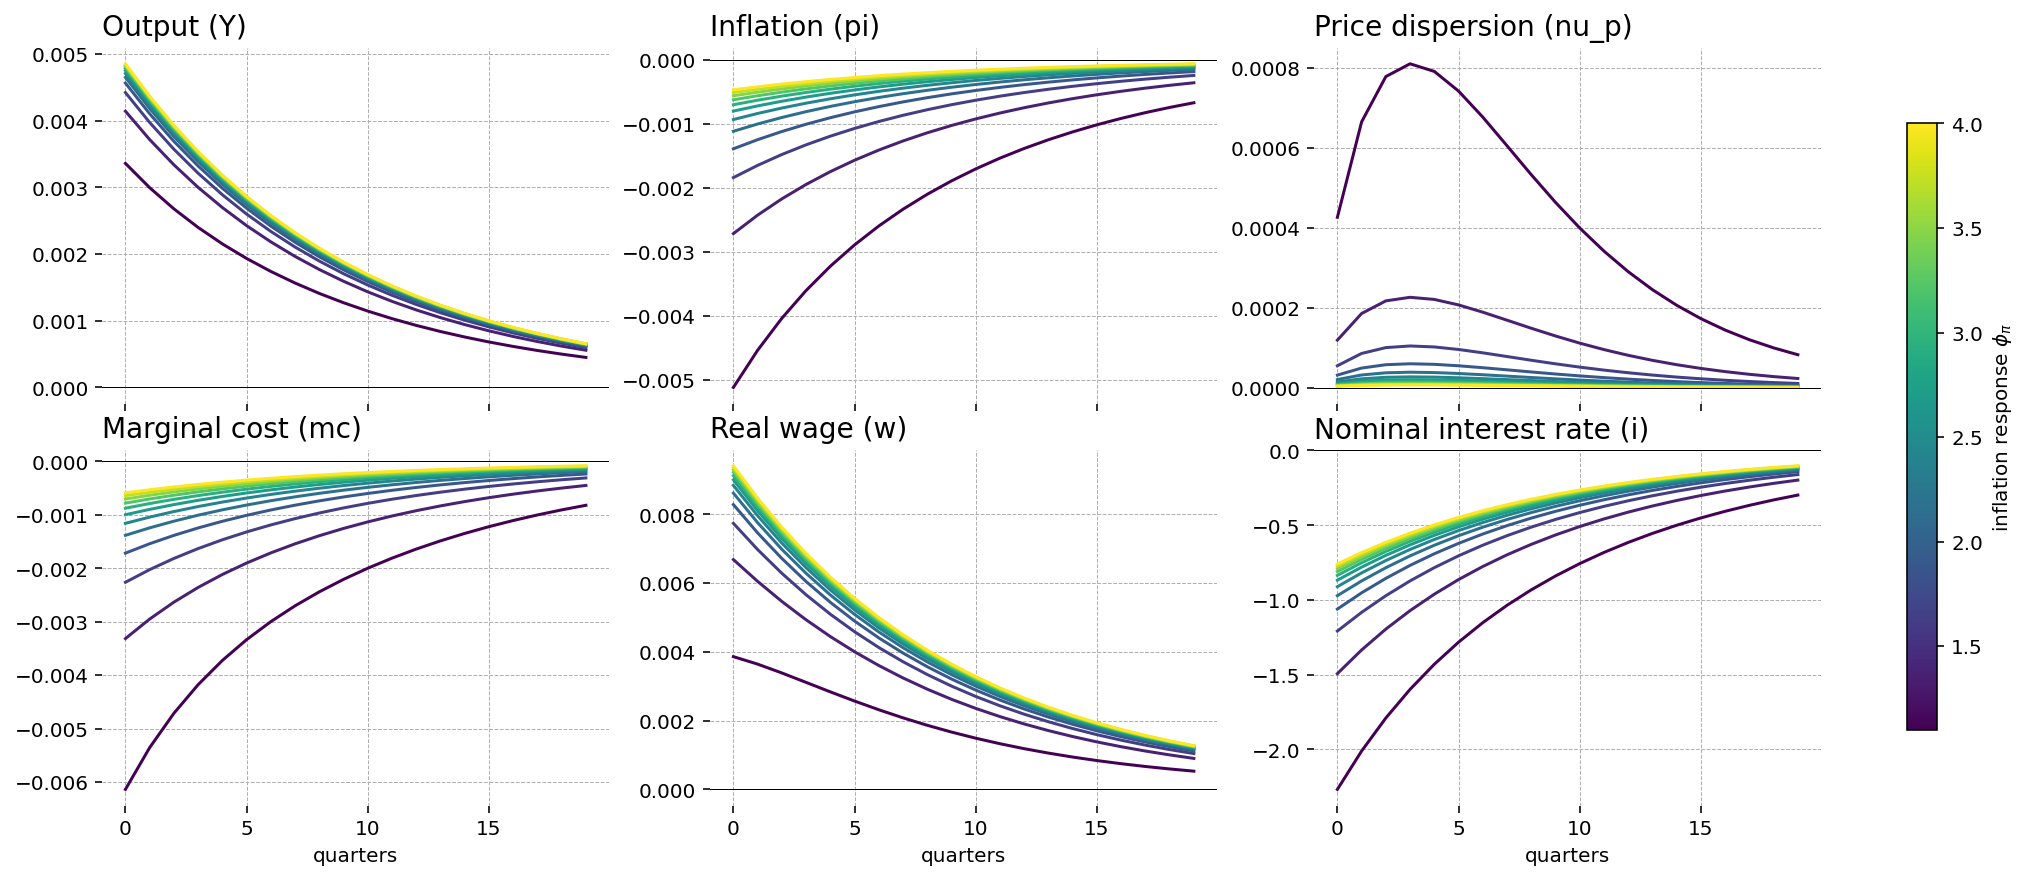

In [15]:
inflation_sweep = technology_responses("phi_pi", np.linspace(1.1, 4.0, 12), phi_Y=0.0)
plot_response_sweep(inflation_sweep, "phi_pi", r"inflation response $\phi_\pi$");

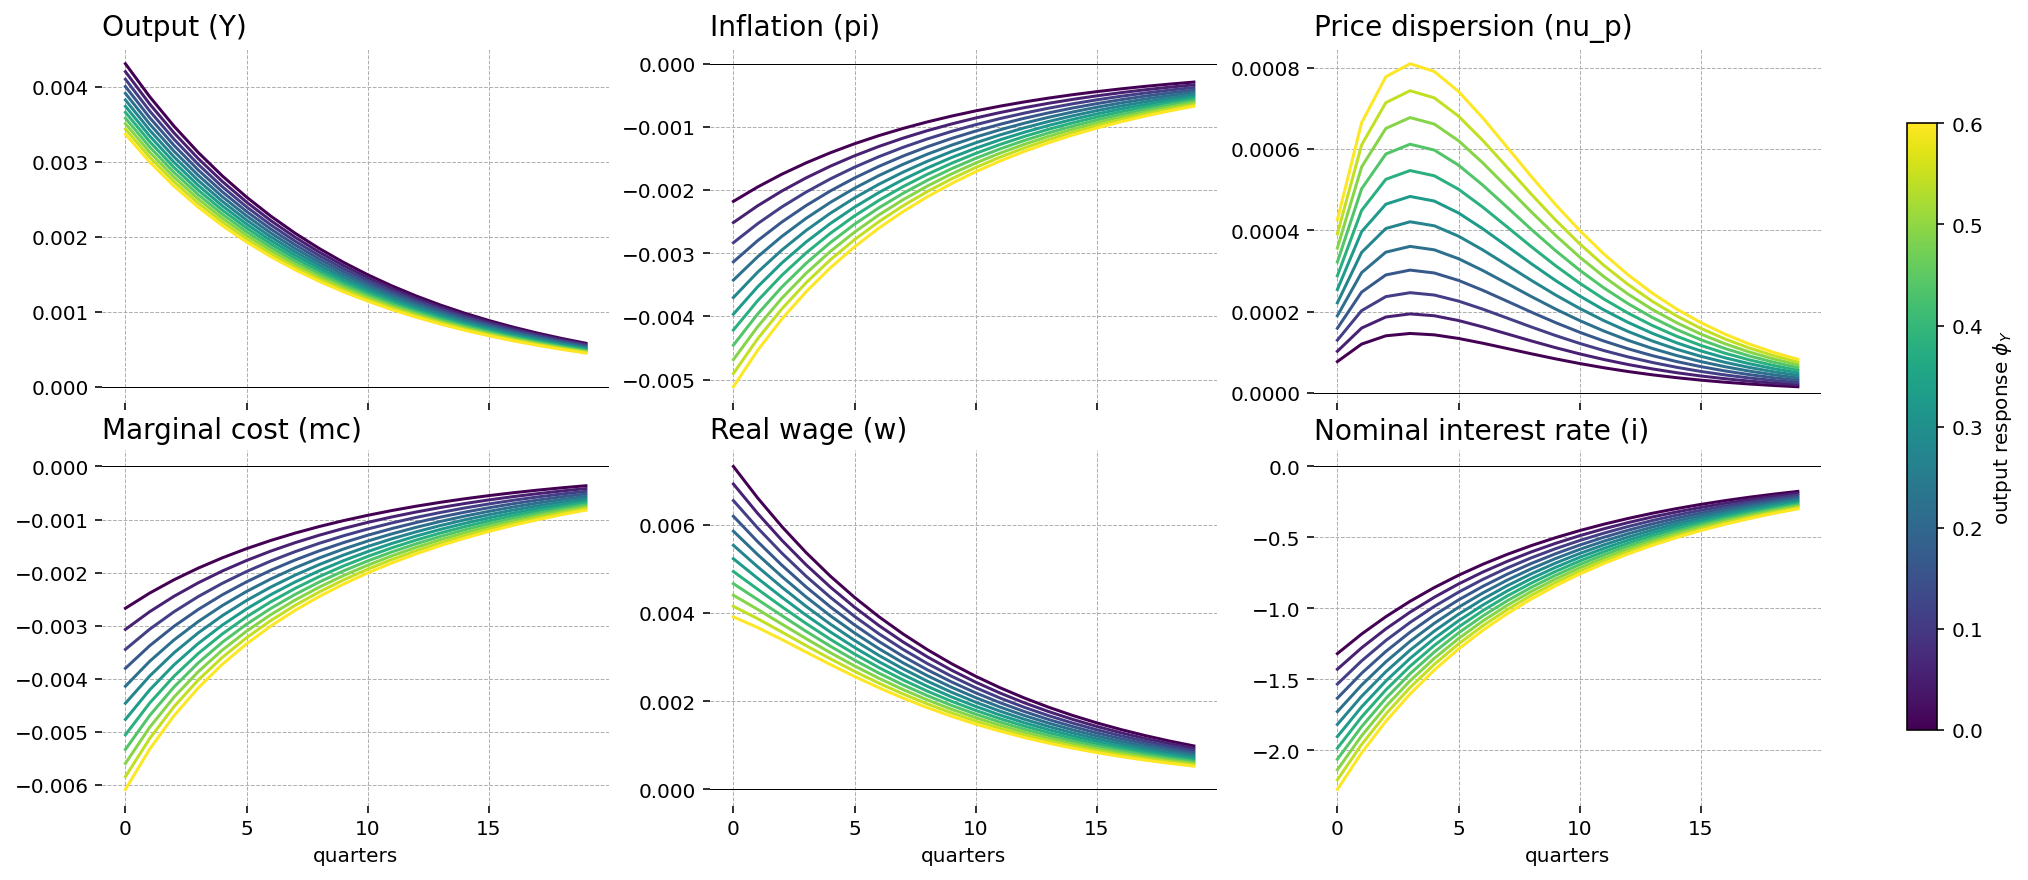

In [16]:
output_sweep = technology_responses("phi_Y", np.linspace(0.0, 0.6, 12), phi_pi=1.5)
plot_response_sweep(output_sweep, "phi_Y", r"output response $\phi_Y$");

## What Second Order Cannot Do

At second order, risk moves average outcomes, but it moves them by a constant. The risk correction $g_{\sigma\sigma}$ does not depend on the state, so the precautionary motive is the same in a recession as in a boom, and a change in the volatility of shocks only shifts the stochastic steady state. Effects of risk that vary over time, such as the response to an uncertainty shock or a time-varying risk premium, enter through the third-order term $g_{x\sigma\sigma}$. That is why studies of volatility shocks, such as Fernandez-Villaverde, Guerron-Quintana, Rubio-Ramirez and Uribe {cite:p}`fernandez-villaverde-2011` and Basu and Bundick {cite:p}`basu-bundick-2017`, solve their models at third order.

## References

```{bibliography}
```

In [17]:
%load_ext watermark
%watermark -n -u -v -iv -w -p gEconpy

Last updated: Sat, 24 Oct 2026

Python implementation: CPython
Python version       : 3.13.13
IPython version      : 9.14.1

gEconpy: 2.2.1.dev2+gaf033cd43

arviz     : 1.3.0
gEconpy   : 2.2.1.dev2+gaf033cd43
matplotlib: 3.10.9
numpy     : 2.4.6
pandas    : 3.0.3
pytensor  : 3.3.4
xarray    : 2026.4.0

Watermark: 2.6.0

